In [9]:
!pip install pandas
!pip install numpy

import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.options.display.float_format = '{:.2f}'.format


In [2]:
#call the Dataframe - 'df'
df= pd.read_csv ('retail_outlets.csv', encoding = 'latin-1')
#.head reduces the output
df.head(1)

,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
0,1079,East,Town,5053.2855,945.839116,8264.861349,309.758037,26.886747,77.678159,97.759093,2.04518,48358.887458,Autumn,37269.08


In [3]:
df.columns
df.dtypes

StoreID                    int64
Region                       str
StoreType                    str
MarketingSpend           float64
Footfall                 float64
OnlineTraffic            float64
StaffHours               float64
DiscountRate             float64
CustomerSatisfaction     float64
InventoryAvailability    float64
CompetitorDistance       float64
PreviousMonthSales       float64
Season                       str
SalesRevenue             float64
dtype: object

In [4]:
df.isnull().sum()

StoreID                    0
Region                     0
StoreType                  0
MarketingSpend           359
Footfall                   0
OnlineTraffic            354
StaffHours                 0
DiscountRate               0
CustomerSatisfaction     359
InventoryAvailability    357
CompetitorDistance         0
PreviousMonthSales         0
Season                     0
SalesRevenue               0
dtype: int64

In [5]:
df.shape

(5100, 14)

In [6]:
print(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

100


In [7]:
cols = ['MarketingSpend', 'OnlineTraffic', 'CustomerSatisfaction', 'InventoryAvailability']
df[cols] = df[cols].fillna(df[cols].median())

In [11]:
## Check the categorical columns:
for c in ['Region', 'StoreType', 'Season']:
    print(df[c].value_counts(dropna=False), '\n')

Region
North    1274
East     1257
South    1250
West     1219
Name: count, dtype: int64 

StoreType
Mall           1697
Retail Park    1686
Town           1617
Name: count, dtype: int64 

Season
Summer    1271
Spring    1270
Autumn    1233
Winter    1226
Name: count, dtype: int64 



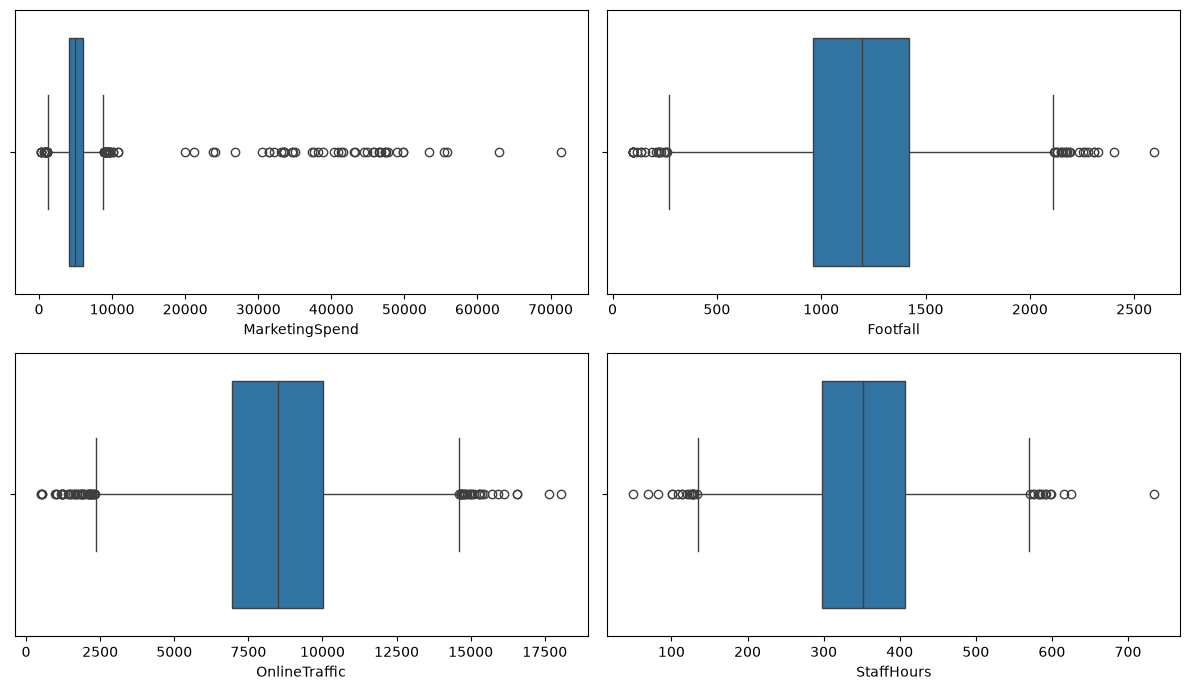

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, ['MarketingSpend', 'Footfall', 'OnlineTraffic', 'StaffHours']):
    sns.boxplot(x=df[col], ax=ax)
plt.tight_layout(); plt.show()

low, high = df['MarketingSpend'].quantile([0.01, 0.99])
df['MarketingSpend'] = df['MarketingSpend'].clip(low, high)

In [13]:
print(df.isnull().sum().sum(), df.duplicated().sum(), df.shape)

0 0 (5000, 14)


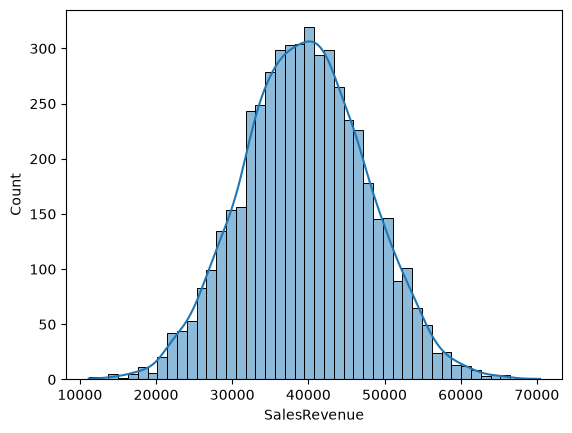

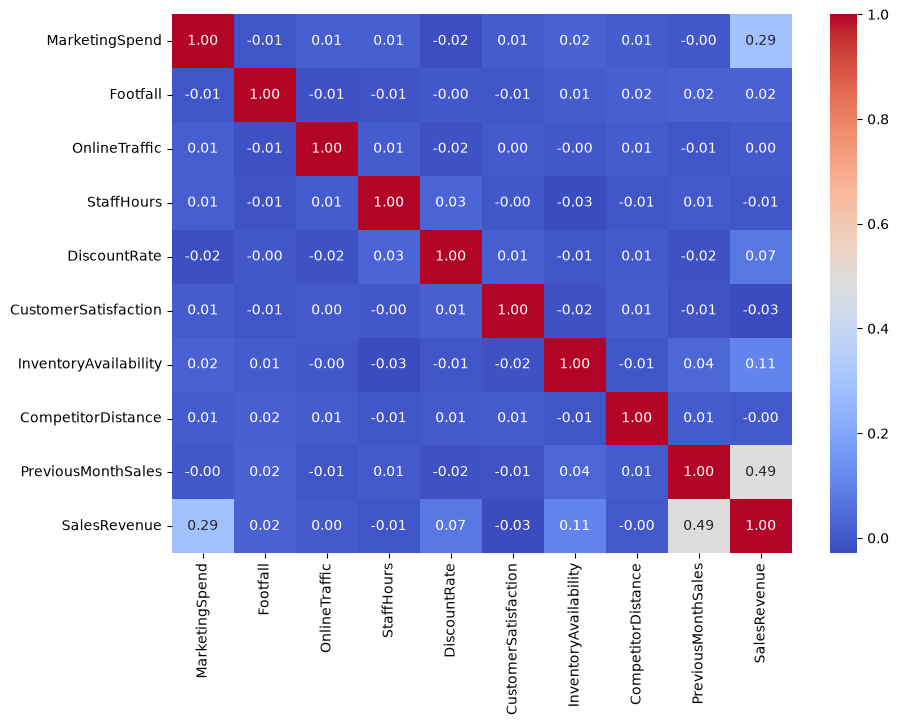

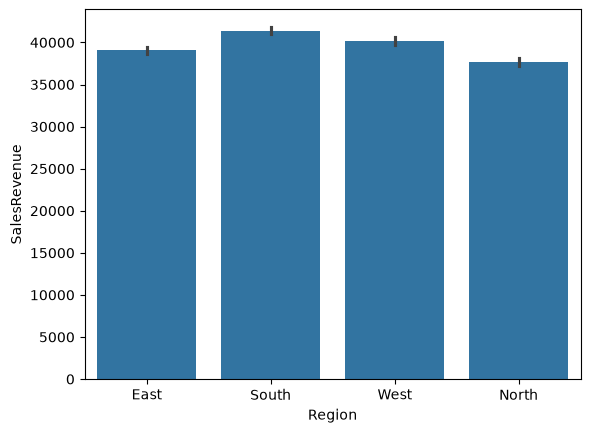

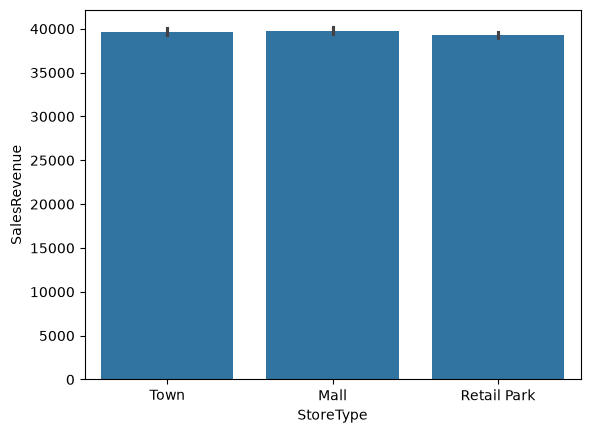

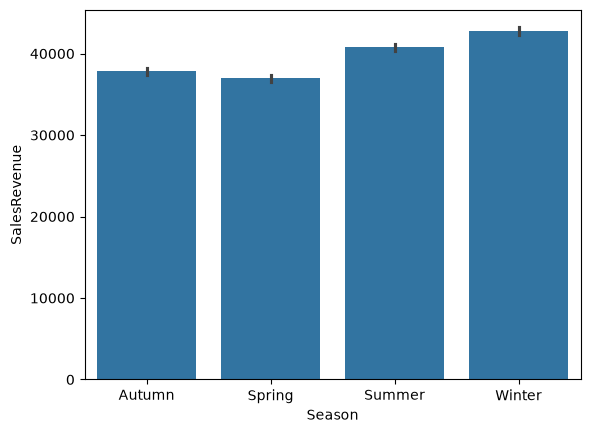

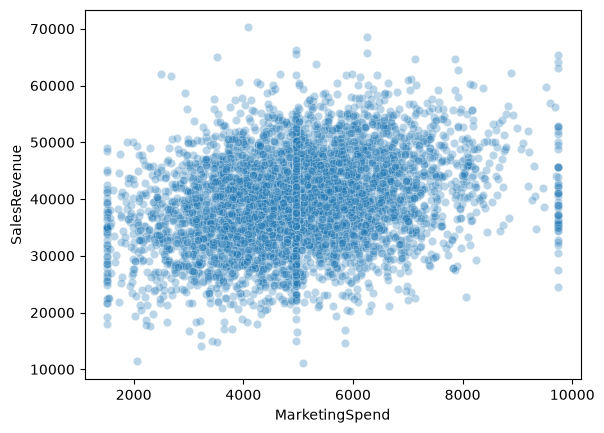

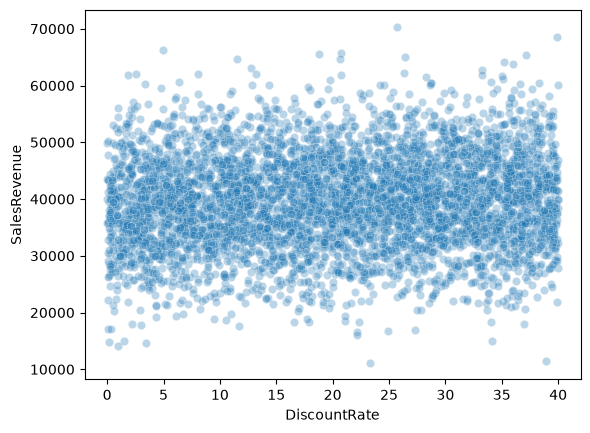

In [14]:
df.describe().T

# Distribution of the target
sns.histplot(df['SalesRevenue'], kde=True); plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes('number').drop(columns='StoreID').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

# Sales by category
for c in ['Region', 'StoreType', 'Season']:
    sns.barplot(data=df, x=c, y='SalesRevenue'); plt.show()

# Key relationships
sns.scatterplot(data=df, x='MarketingSpend', y='SalesRevenue', alpha=0.3); plt.show()
sns.scatterplot(data=df, x='DiscountRate', y='SalesRevenue', alpha=0.3); plt.show()

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df.drop(columns=['SalesRevenue', 'StoreID'])
y = df['SalesRevenue']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

cat = ['Region', 'StoreType', 'Season']
num = [c for c in X.columns if c not in cat]
prep = ColumnTransformer([('cat', OneHotEncoder(drop='first'), cat),
                          ('num', StandardScaler(), num)])

models = {
    'Baseline (mean)': DummyRegressor(),
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

results = []
for name, m in models.items():
    pipe = Pipeline([('prep', prep), ('model', m)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append([name, mean_absolute_error(y_test, pred),
                    mean_squared_error(y_test, pred) ** 0.5, r2_score(y_test, pred)])

pd.DataFrame(results, columns=['Model', 'MAE', 'RMSE', 'R2'])

,Model,MAE,RMSE,R2
0,Baseline (mean),6658.99,8256.28,-0.00
1,Linear Regression,4942.95,6172.85,0.44
2,Random Forest,5161.67,6440.21,0.39


In [16]:
## Model Comparison

#Both models performed clearly better than the baseline, which simply predicts the average sales figure (R² ≈ 0.00). This shows the store features contain real predictive information about revenue.

#Linear Regression performed slightly better than Random Forest (R² ≈ .44 vs .39, MAE ≈ 4943 vs 5162). The difference is small, but it suggests the main relationships in the data are largely linear. For example, stores with higher previous month sales and higher marketing spend tend to earn more revenue in a fairly steady way, which a linear model captures well.

#The scatter plots also show the data is very noisy, with points widely spread around any trend. This explains why even the best model only reaches an R² of about 0.44, meaning over half of the variation in sales is not explained by the available features. Noise like this can also cause a flexible model such as Random Forest to overfit, learning random patterns in the training data that do not carry over to new data.

#Linear Regression is also easier to interpret, which is valuable when explaining the drivers of sales to business stakeholders.